## VAE 3D

In [ ]:
import os
import sys

# Localizamos dónde tiene Conda los archivos d ela gráfica
ruta_cuda = os.path.join(sys.prefix, 'Library', 'bin')

# Forzamos a Windows y a VS Code a meter esta ruta en su sistema principal
os.environ['PATH'] = ruta_cuda + os.pathsep + os.environ['PATH']

# importamos TensorFlow (con el camino ya despejado)
import tensorflow as tf

print("¿TensorFlow detecta la GPU?:", tf.test.is_built_with_cuda())
print("Dispositivos GPU disponibles:", tf.config.list_physical_devices('GPU'))

¿TensorFlow detecta la GPU?: True
Dispositivos GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf


gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        # Obligamos a TF a coger memoria solo cuando la necesite, no toda de golpe
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("Memoria dinámica activada para la GPU")
    except RuntimeError as e:
        print(e)
        
print("¿TensorFlow detecta la GPU?:", tf.test.is_built_with_cuda())
print("Dispositivos GPU disponibles:", tf.config.list_physical_devices('GPU'))

Memoria dinámica activada para la GPU
¿TensorFlow detecta la GPU?: True
Dispositivos GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [13]:
import numpy as np
import h5py
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from mpl_toolkits.mplot3d import Axes3D
import keras
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv3D, MaxPooling3D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
with h5py.File('archive/full_dataset_vectors.h5', 'r') as dataset:
    X_train = dataset["X_train"][:]
    X_test = dataset["X_test"][:]
    

X_train = X_train.reshape(-1, 16, 16, 16, 1) # Añadimos el 1 al final para el canald e color
X_test = X_test.reshape(-1, 16, 16, 16, 1)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import scipy.ndimage 

class VisorReconstruccion3D(tf.keras.callbacks.Callback):
    def __init__(self, datos_prueba, num_ejemplos=4, threshold_orig=0.05, threshold_recon=0.1, factor_zoom=2): 
        super().__init__()
        self.datos_prueba = datos_prueba[:num_ejemplos]
        self.num_ejemplos = num_ejemplos
        self.threshold_orig = threshold_orig
        self.threshold_recon = threshold_recon
        self.factor_zoom = factor_zoom

    def on_epoch_end(self, epoch, logs=None):
        
        # Visualizamos de 5 en 5
        if (epoch + 4) % 5 != 0: 
            return 
            
        reconstrucciones = self.model.predict(self.datos_prueba, verbose=0)
        
        fig = plt.figure(figsize=(15, 6))
        fig.suptitle(f"Evolución Volumétrica - Época {epoch + 1}", fontsize=16)
        
        for i in range(self.num_ejemplos):
            
            # Visualizado original
            ax_orig = fig.add_subplot(2, self.num_ejemplos, i + 1, projection='3d')
            
            cubo_orig_bruto = self.datos_prueba[i, :, :, :, 0]
            cubo_orig_suave = scipy.ndimage.zoom(cubo_orig_bruto, self.factor_zoom, order=1)
            cubo_orig = cubo_orig_suave > self.threshold_orig
            
            ax_orig.voxels(cubo_orig, facecolors='#1f77b4', edgecolor=(0, 0, 0, 0.05), alpha=0.9)
            ax_orig.view_init(elev=30, azim=-60) 
            ax_orig.axis('off')
            if i == 0: ax_orig.set_title("Original (HD)")
            
            # Visualizado reconstrucción
            ax_recon = fig.add_subplot(2, self.num_ejemplos, i + 1 + self.num_ejemplos, projection='3d')
            
            cubo_recon_bruto = reconstrucciones[i, :, :, :, 0]
            cubo_recon_suave = scipy.ndimage.zoom(cubo_recon_bruto, self.factor_zoom, order=1)
            cubo_recon = cubo_recon_suave > self.threshold_recon
            
            ax_recon.voxels(cubo_recon, facecolors='teal', edgecolor=(0, 0, 0, 0.05), alpha=0.9)
            ax_recon.view_init(elev=30, azim=-60) 
            ax_recon.axis('off')
            if i == 0: ax_recon.set_title("Reconstrucción (Gorda)")
            
        plt.tight_layout()
        plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers

# Capa de muestreo
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        # eps = torch.randn_like(std)
        epsilon = tf.keras.backend.random_normal(shape=(batch, dim))
        # return mu + eps * std
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

# Encoder
def build_encoder(input_shape=(16, 16, 16, 1), latent_dim=32):
    encoder_inputs = tf.keras.Input(shape=input_shape)
    
    # Capa 1: Conv -> BatchNorm -> LeakyReLU (De 16x16 a 8x8)
    x = layers.Conv3D(32, kernel_size=4, strides=2, padding="same", use_bias=False)(encoder_inputs)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)
    
    # Capa 2: Conv -> BatchNorm -> LeakyReLU (De 8x8 a 4x4)
    x = layers.Conv3D(64, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)
    
    # Capa 3: Conv -> BatchNorm -> LeakyReLU (De 4x4 a 2x2)
    x = layers.Conv3D(128, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)
    
    shape_before_flattening = tf.keras.backend.int_shape(x)[1:] 
    
    # Equivalente a: h = self.net(x).view(x.size(0), -1)
    x = layers.Flatten()(x)
    
    # Equivalente a: self.fc_mu y self.fc_logvar
    z_mean = layers.Dense(latent_dim, name="z_mean")(x)
    z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
    
    z = Sampling()([z_mean, z_log_var])
    
    return tf.keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder"), shape_before_flattening

# Decoder
def build_decoder(shape_before_flattening, latent_dim=32):
    latent_inputs = tf.keras.Input(shape=(latent_dim,))
    
    # Equivalente a: self.fc(z).view(...)
    num_neurons = shape_before_flattening[0] * shape_before_flattening[1] * shape_before_flattening[2] * shape_before_flattening[3]
    x = layers.Dense(num_neurons)(latent_inputs)
    x = layers.Reshape(shape_before_flattening)(x)
    
    # Capa 1: ConvTranspose -> BatchNorm -> LeakyReLU (De 2x2 a 4x4)
    x = layers.Conv3DTranspose(64, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)
    
    # Capa 2: ConvTranspose -> BatchNorm -> LeakyReLU (De 4x4 a 8x8)
    x = layers.Conv3DTranspose(32, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)
    
    # Capa 3: ConvTranspose -> Tanh (De 8x8 a 16x16)
    decoder_outputs = layers.Conv3DTranspose(1, kernel_size=4, strides=2, padding="same", activation="sigmoid")(x)
    
    return tf.keras.Model(latent_inputs, decoder_outputs, name="decoder")

In [17]:
class VAE3D(tf.keras.Model):
    def __init__(self, encoder, decoder, beta=0.01, **kwargs): # Añadido el parámetro beta
        super(VAE3D, self).__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta = beta
        
        self.total_loss_tracker = tf.keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = tf.keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = tf.keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.reconstruction_loss_tracker, self.kl_loss_tracker]

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)
            
            # 1. Pérdida de Reconstrucción (Equivalente a: F.mse_loss(recon_x, x, reduction="sum"))
            # Cambiamos mse por binary_crossentropy
            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(tf.keras.losses.binary_crossentropy(data, reconstruction), axis=(1, 2, 3))
            )
            
            # 2. Pérdida KL (Equivalente a: -0.5 * mean(sum(1 + logvar - mu^2 - exp(logvar), dim=1)))
            kl_loss = -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
            kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))
            
            # 3. Total
            total_loss = reconstruction_loss + self.beta * kl_loss

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        
        return {
            "loss": self.total_loss_tracker.result(),
            "recon_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }
    
    def call(self, inputs):
        z_mean, _, z = self.encoder(inputs)
        return self.decoder(z)

Epoch 1/50
313/313 [==============================] - 162s 91ms/step - loss: 1251.2686 - recon_loss: 1239.4207 - kl_loss: 189.8289 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 2/50
313/313 [==============================] - ETA: 0s - loss: 604.0938 - recon_loss: 597.6124 - kl_loss: 124.9151

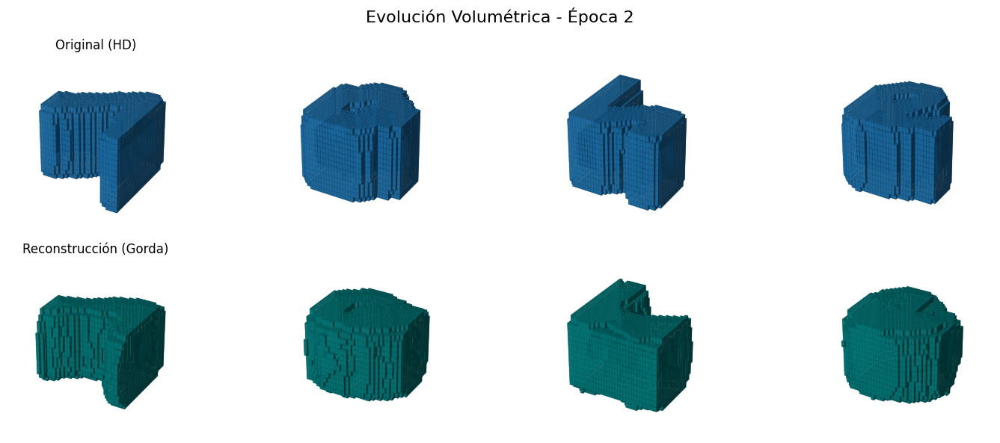

313/313 [==============================] - 73s 235ms/step - loss: 604.0541 - recon_loss: 597.5735 - kl_loss: 124.9151 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 3/50
313/313 [==============================] - 28s 91ms/step - loss: 561.1625 - recon_loss: 555.4533 - kl_loss: 112.5278 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 4/50
313/313 [==============================] - 29s 92ms/step - loss: 538.7309 - recon_loss: 533.2455 - kl_loss: 110.0062 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 5/50
313/313 [==============================] - 29s 93ms/step - loss: 524.2589 - recon_loss: 518.7075 - kl_loss: 111.2490 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 6/50
313/313 [==============================] - 29s 92ms/step - loss: 512.5857 - recon_loss: 507.0336 - kl_loss: 110.403

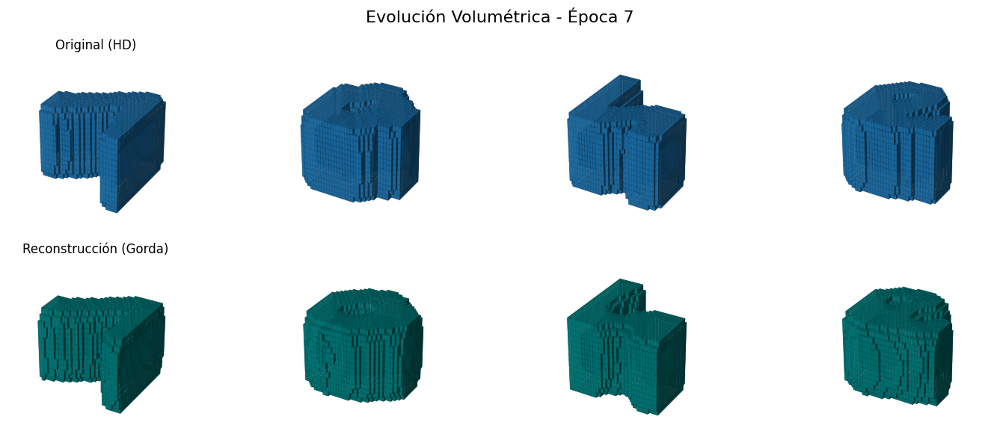

313/313 [==============================] - 78s 250ms/step - loss: 501.1276 - recon_loss: 495.6679 - kl_loss: 109.0676 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 8/50
313/313 [==============================] - 29s 92ms/step - loss: 495.7969 - recon_loss: 490.3543 - kl_loss: 108.3855 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 9/50
313/313 [==============================] - 29s 93ms/step - loss: 491.8802 - recon_loss: 486.4773 - kl_loss: 108.2396 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 10/50
313/313 [==============================] - 29s 94ms/step - loss: 484.1635 - recon_loss: 478.7434 - kl_loss: 108.1961 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 11/50
313/313 [==============================] - 29s 94ms/step - loss: 481.0801 - recon_loss: 475.6769 - kl_loss: 107.5

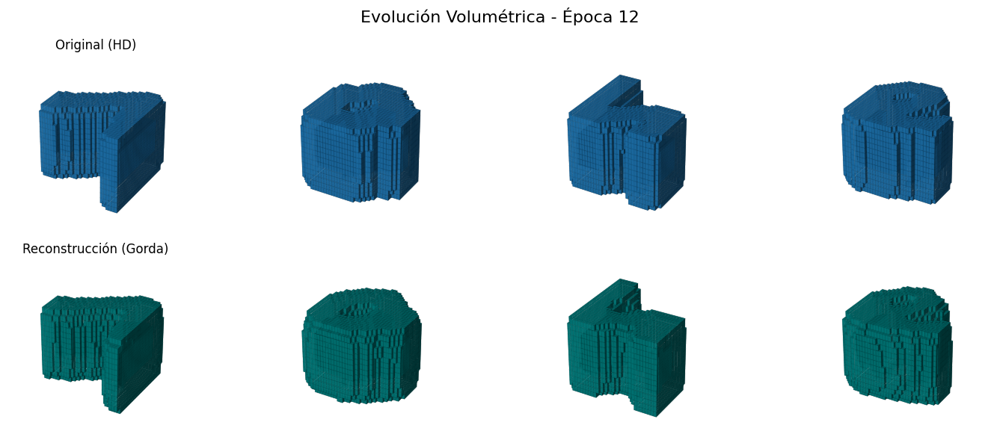

313/313 [==============================] - 80s 255ms/step - loss: 477.3646 - recon_loss: 471.9739 - kl_loss: 107.7725 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 13/50
313/313 [==============================] - 29s 92ms/step - loss: 474.5017 - recon_loss: 469.0994 - kl_loss: 107.6682 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 14/50
313/313 [==============================] - 29s 92ms/step - loss: 471.6440 - recon_loss: 466.2218 - kl_loss: 108.0131 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 15/50
313/313 [==============================] - 29s 92ms/step - loss: 470.0364 - recon_loss: 464.6324 - kl_loss: 107.9846 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 16/50
313/313 [==============================] - 29s 92ms/step - loss: 465.1557 - recon_loss: 459.7670 - kl_loss: 107

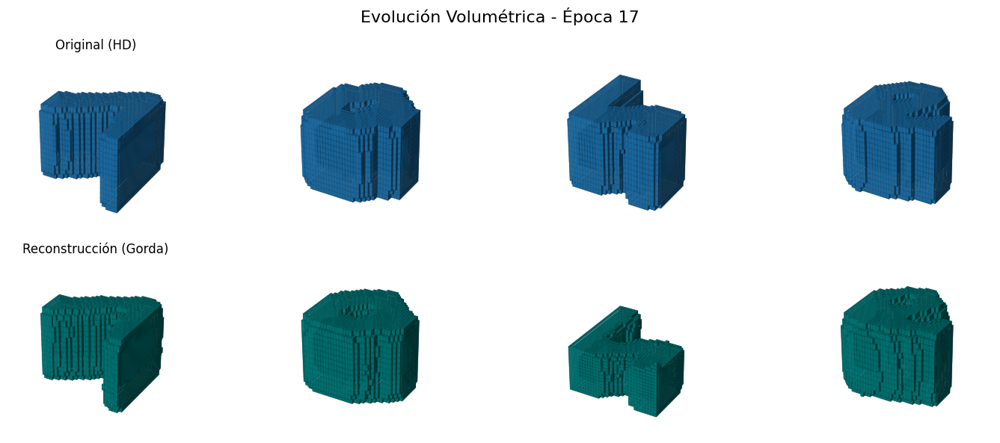

313/313 [==============================] - 82s 261ms/step - loss: 465.9649 - recon_loss: 460.5768 - kl_loss: 107.7076 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 18/50
313/313 [==============================] - 28s 91ms/step - loss: 464.7423 - recon_loss: 459.3589 - kl_loss: 107.6566 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 19/50
313/313 [==============================] - 29s 92ms/step - loss: 463.0125 - recon_loss: 457.5975 - kl_loss: 107.8958 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 20/50
313/313 [==============================] - 29s 92ms/step - loss: 462.2198 - recon_loss: 456.8076 - kl_loss: 108.1595 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 21/50
313/313 [==============================] - 29s 92ms/step - loss: 458.7115 - recon_loss: 453.3098 - kl_loss: 107

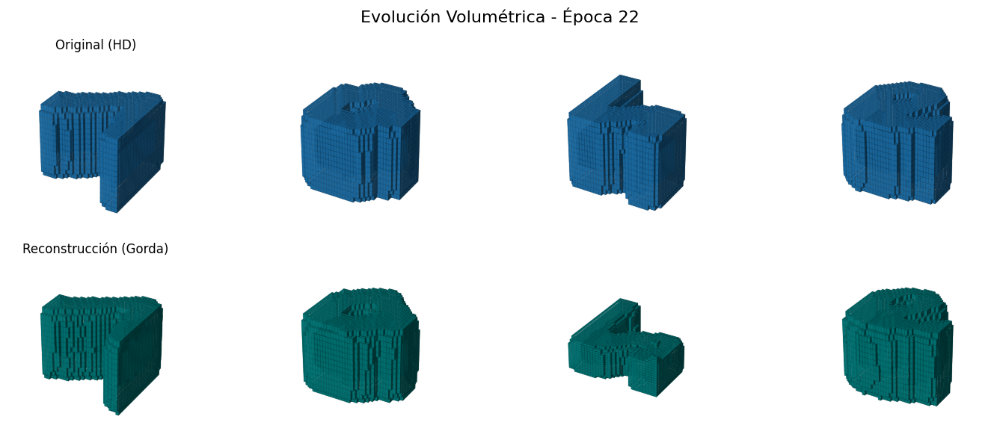

313/313 [==============================] - 82s 261ms/step - loss: 459.2050 - recon_loss: 453.7842 - kl_loss: 107.9826 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 23/50
313/313 [==============================] - 29s 92ms/step - loss: 458.7150 - recon_loss: 453.3164 - kl_loss: 107.9932 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 24/50
313/313 [==============================] - 29s 92ms/step - loss: 459.1095 - recon_loss: 453.7101 - kl_loss: 107.9178 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 25/50
313/313 [==============================] - 29s 92ms/step - loss: 456.2673 - recon_loss: 450.8739 - kl_loss: 107.9319 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 26/50
313/313 [==============================] - 29s 92ms/step - loss: 454.1028 - recon_loss: 448.6899 - kl_loss: 108

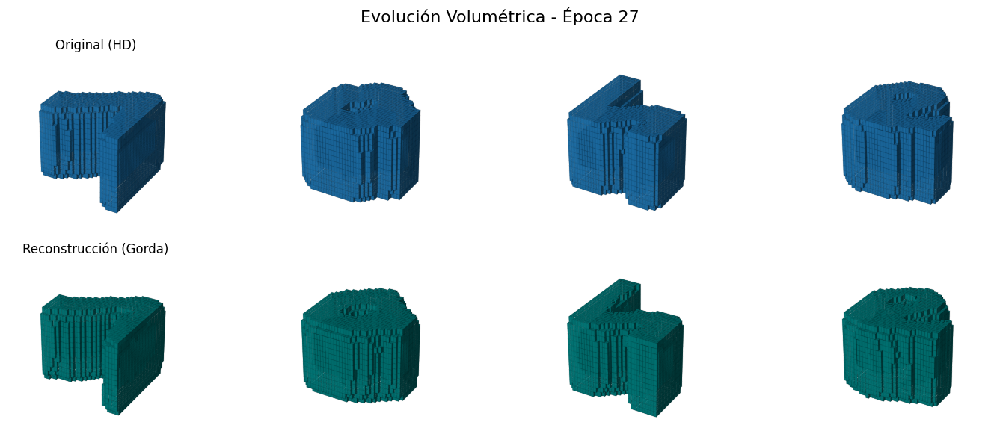

313/313 [==============================] - 81s 259ms/step - loss: 456.4330 - recon_loss: 451.0143 - kl_loss: 108.1039 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 28/50
313/313 [==============================] - 29s 92ms/step - loss: 453.3780 - recon_loss: 447.9774 - kl_loss: 108.0083 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 29/50
313/313 [==============================] - 29s 92ms/step - loss: 452.1718 - recon_loss: 446.7741 - kl_loss: 107.9521 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 30/50
313/313 [==============================] - 29s 93ms/step - loss: 452.3640 - recon_loss: 446.9383 - kl_loss: 108.2661 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 31/50
313/313 [==============================] - 29s 93ms/step - loss: 451.6874 - recon_loss: 446.2890 - kl_loss: 107

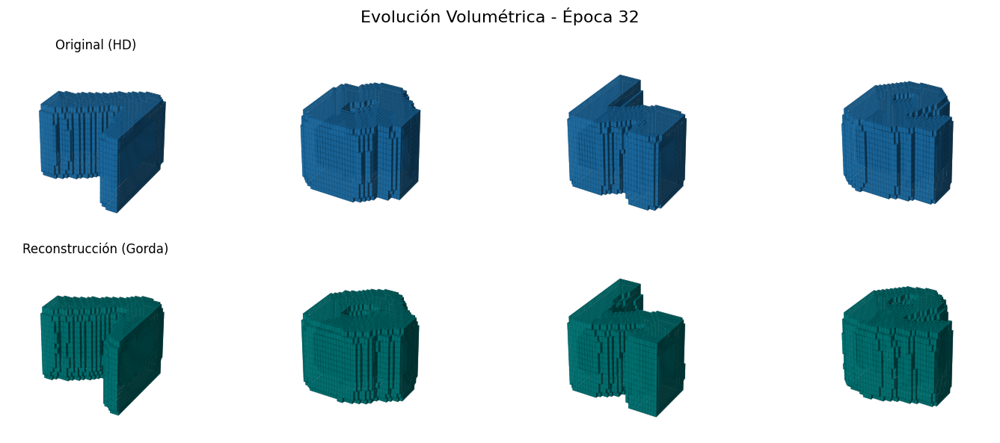

313/313 [==============================] - 81s 258ms/step - loss: 450.9361 - recon_loss: 445.5154 - kl_loss: 108.3404 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 33/50
313/313 [==============================] - 29s 93ms/step - loss: 450.4691 - recon_loss: 445.0544 - kl_loss: 108.1124 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 34/50
313/313 [==============================] - 29s 93ms/step - loss: 447.7382 - recon_loss: 442.3173 - kl_loss: 108.1692 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 35/50
313/313 [==============================] - 28s 91ms/step - loss: 451.1280 - recon_loss: 445.7126 - kl_loss: 108.2367 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 36/50
313/313 [==============================] - 29s 93ms/step - loss: 448.6843 - recon_loss: 443.2664 - kl_loss: 108

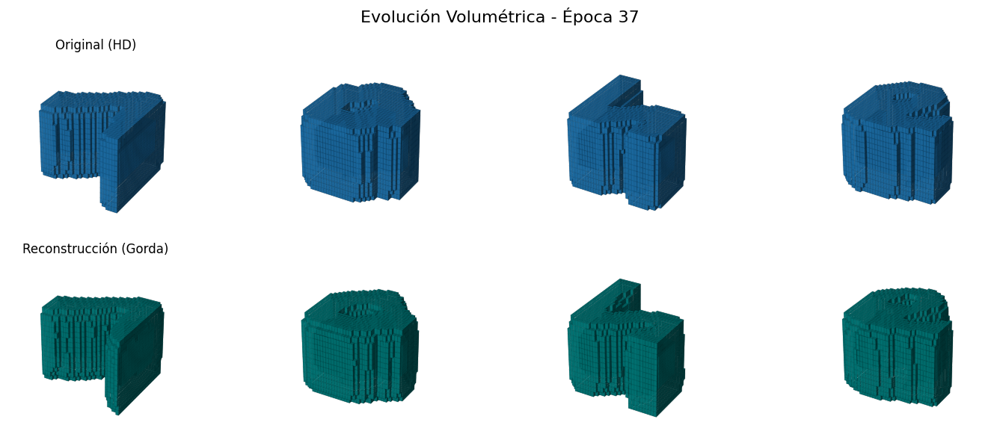

313/313 [==============================] - 80s 257ms/step - loss: 447.0957 - recon_loss: 441.6829 - kl_loss: 108.2195 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 38/50
313/313 [==============================] - 29s 92ms/step - loss: 448.2596 - recon_loss: 442.8392 - kl_loss: 108.3159 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 39/50
313/313 [==============================] - 29s 93ms/step - loss: 449.5974 - recon_loss: 444.1651 - kl_loss: 108.2617 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 40/50
313/313 [==============================] - 29s 93ms/step - loss: 445.9808 - recon_loss: 440.5577 - kl_loss: 108.4029 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 41/50
313/313 [==============================] - 29s 94ms/step - loss: 447.2041 - recon_loss: 441.7912 - kl_loss: 108

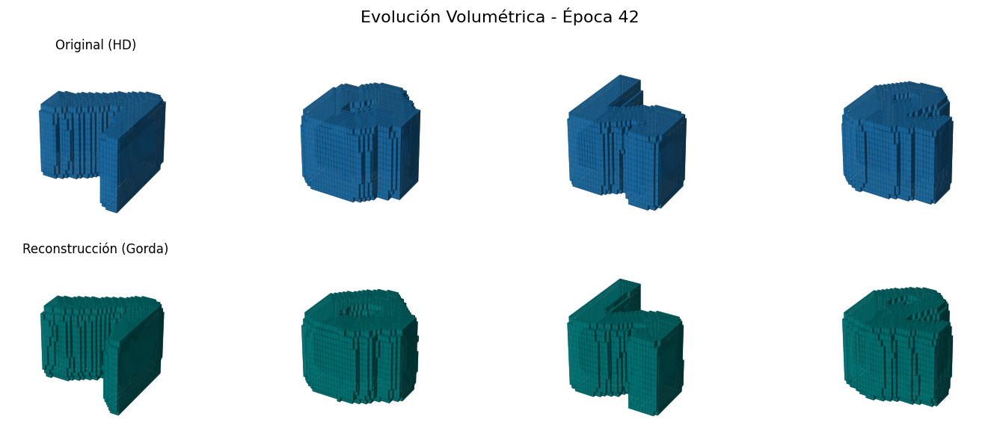

313/313 [==============================] - 1370s 4s/step - loss: 445.0350 - recon_loss: 439.6202 - kl_loss: 108.1652 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 43/50
313/313 [==============================] - 29s 91ms/step - loss: 444.7255 - recon_loss: 439.3227 - kl_loss: 108.1325 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 44/50
313/313 [==============================] - 29s 93ms/step - loss: 446.7472 - recon_loss: 441.3278 - kl_loss: 108.3596 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 45/50
313/313 [==============================] - 29s 92ms/step - loss: 444.7055 - recon_loss: 439.2903 - kl_loss: 108.3262 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 46/50
313/313 [==============================] - 29s 92ms/step - loss: 445.6955 - recon_loss: 440.2877 - kl_loss: 108.

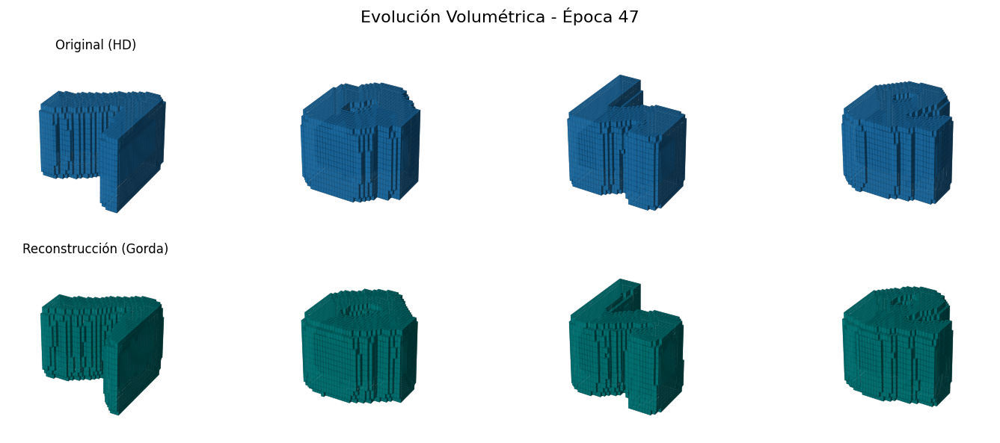

313/313 [==============================] - 81s 261ms/step - loss: 445.1268 - recon_loss: 439.7124 - kl_loss: 108.1815 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 48/50
313/313 [==============================] - 28s 90ms/step - loss: 445.6292 - recon_loss: 440.2019 - kl_loss: 108.3946 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 49/50
313/313 [==============================] - 29s 92ms/step - loss: 446.3184 - recon_loss: 440.9000 - kl_loss: 108.2327 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00
Epoch 50/50
313/313 [==============================] - 29s 93ms/step - loss: 445.2980 - recon_loss: 439.8833 - kl_loss: 108.2028 - val_total_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00 - val_kl_loss: 0.0000e+00


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

# Instanciamos las piezas
input_shape = X_train.shape[1:] 
encoder, shape_before_flattening = build_encoder(input_shape=input_shape, latent_dim=32)
decoder = build_decoder(shape_before_flattening, latent_dim=32)

# Montamos el VAE
vae = VAE3D(encoder, decoder, beta=0.05)
vae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005))

# Mantenemos tus ejemplos personalizados
indices_personalizados = [0, 6, 2, 22] 
mis_4_ejemplos = X_test[indices_personalizados]

# Actualizamos el visor
visor_callback = VisorReconstruccion3D(
    datos_prueba=mis_4_ejemplos, 
    num_ejemplos=4, 
    threshold_orig=0.05, 
    threshold_recon=0.1,  # Muy bajo para que dibuje prácticamente todo
    factor_zoom=2         # HD activado
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    min_delta=1.2,        # Vigilamos el error total en los datos de test
    patience=4,                # Si pasan 5 épocas seguidas sin mejorar, cortamos
    restore_best_weights=True  # El modelo retrocede y se queda con los pesos de su mejor época
)

# Entrenamiento
history = vae.fit(
    X_train, X_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, X_test),
    callbacks=[visor_callback, early_stopping] # Usamos los 2 a la vez
)

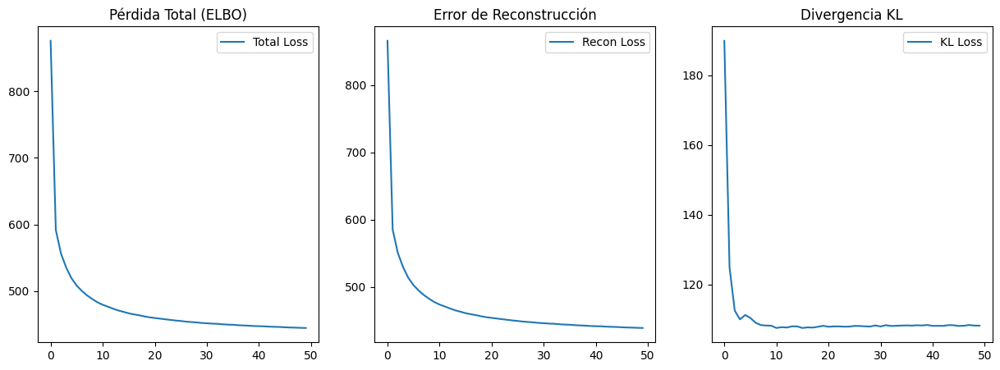

In [9]:
# ----------------------------
# 1. Visualización de Pérdidas
# ----------------------------
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], label='Total Loss')
plt.title('Pérdida Total (ELBO)')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(history.history['recon_loss'], label='Recon Loss')
plt.title('Error de Reconstrucción')
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(history.history['kl_loss'], label='KL Loss')
plt.title('Divergencia KL')
plt.legend()

plt.show()

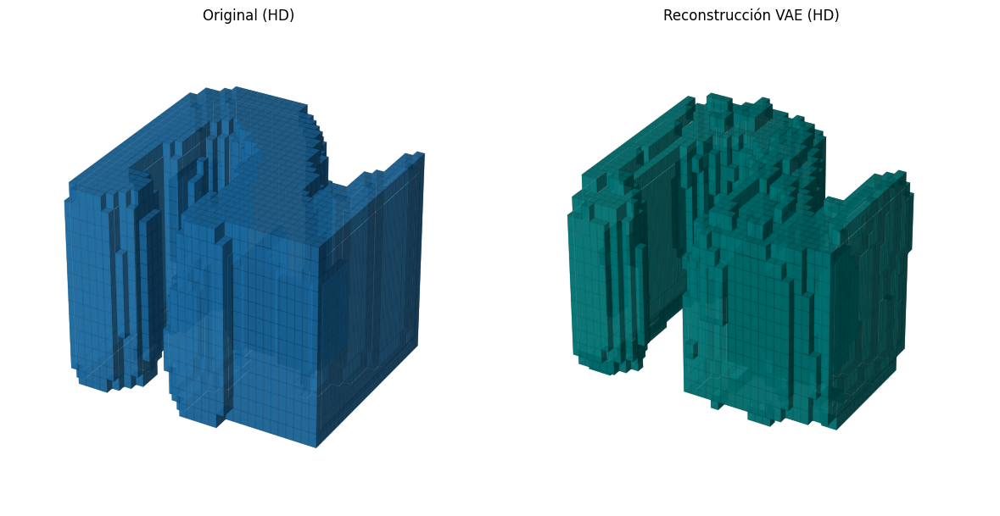

In [ ]:
import scipy.ndimage


# Visualización Final (HD)

def visualizar_resultado_hd(data, threshold_orig=0.05, threshold_recon=0.2, factor_zoom=2):
    fig = plt.figure(figsize=(12, 6))
    
    # Original
    ax1 = fig.add_subplot(121, projection='3d')
    cubo_orig_suave = scipy.ndimage.zoom(data[0,:,:,:,0], factor_zoom, order=1)
    ax1.voxels(cubo_orig_suave > threshold_orig, facecolors='#1f77b4', edgecolor=(0,0,0,0.05), alpha=0.8)
    ax1.set_title("Original (HD)")
    ax1.view_init(elev=30, azim=-60)
    ax1.axis('off')
    
    # Reconstrucción
    recon = vae.predict(data[:1], verbose=0)
    ax2 = fig.add_subplot(122, projection='3d')
    cubo_recon_suave = scipy.ndimage.zoom(recon[0,:,:,:,0], factor_zoom, order=1)
    ax2.voxels(cubo_recon_suave > threshold_recon, facecolors='teal', edgecolor=(0,0,0,0.05), alpha=0.8)
    ax2.set_title("Reconstrucción VAE (HD)")
    ax2.view_init(elev=30, azim=-60)
    ax2.axis('off')
    
    plt.tight_layout()
    plt.show()

visualizar_resultado_hd(X_test[30:31])

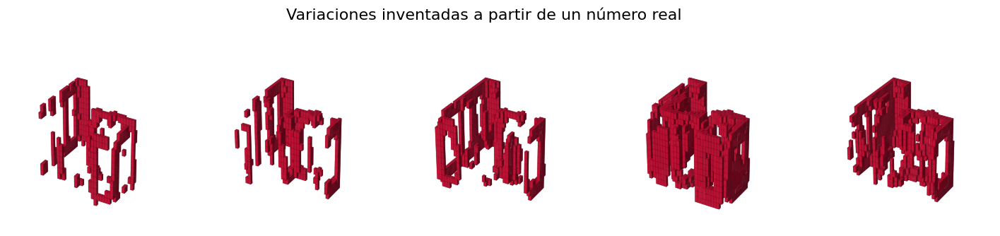

In [ ]:
def generar_desde_semilla_real(vae_model, cubo_real, n_variaciones=5, nivel_ruido=0.5, factor_zoom=2, threshold=0.5):
    # Pasamos el cubo real por el Encoder para descubrir sus coordenadas exactas (z_mean)
    z_mean, _, _ = vae_model.encoder.predict(np.expand_dims(cubo_real, 0), verbose=0)
    
    # Creamos variaciones sumándole un poco de ruido a esa coordenada exacta
    z_variaciones = z_mean + np.random.normal(loc=0.0, scale=nivel_ruido, size=(n_variaciones, z_mean.shape[1]))
    
    #El Decoder dibuja las variaciones
    muestras = vae_model.decoder.predict(z_variaciones, verbose=0)
    
    fig = plt.figure(figsize=(18, 4))
    fig.suptitle(f"Variaciones inventadas a partir de un número real", fontsize=16)
    
    for i in range(n_variaciones):
        ax = fig.add_subplot(1, n_variaciones, i + 1, projection='3d')
        cubo_suave = scipy.ndimage.zoom(muestras[i,:,:,:,0], factor_zoom, order=1)
        ax.voxels(cubo_suave > threshold, facecolors='crimson', edgecolor=(0,0,0,0.05), alpha=0.9)
        ax.view_init(elev=30, azim=-60)
        ax.axis('off')
        
    plt.show()

# Cogemos el ejemplo 10 de los datos de prueba como "semilla"
generar_desde_semilla_real(vae, X_test[2])

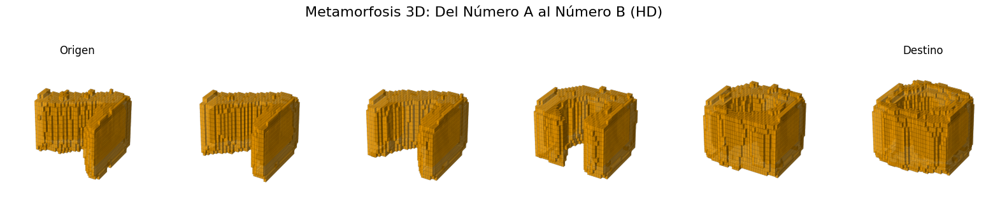

In [ ]:

# Interpolación 3D 

def interpolacion_3d_hd(vae_model, cubo_a, cubo_b, n_pasos=6, factor_zoom=2):
    z1, _, _ = vae_model.encoder.predict(np.expand_dims(cubo_a, 0), verbose=0)
    z2, _, _ = vae_model.encoder.predict(np.expand_dims(cubo_b, 0), verbose=0)
    
    alphas = np.linspace(0, 1, n_pasos)
    z_interp = np.array([(1-a)*z1[0] + a*z2[0] for a in alphas])
    
    cubos_interp = vae_model.decoder.predict(z_interp, verbose=0)
    
    fig = plt.figure(figsize=(20, 4))
    fig.suptitle("Metamorfosis 3D: Del Número A al Número B (HD)", fontsize=16)
    
    for i in range(n_pasos):
        ax = fig.add_subplot(1, n_pasos, i + 1, projection='3d')
        cubo_hd = scipy.ndimage.zoom(cubos_interp[i,:,:,:,0], factor_zoom, order=1)
        ax.voxels(cubo_hd > 0.2, facecolors='orange', edgecolor=(0,0,0,0.05), alpha=0.7)
        ax.view_init(elev=30, azim=-60)
        ax.axis('off')
        if i == 0: ax.set_title("Origen")
        if i == n_pasos-1: ax.set_title("Destino")
        
    plt.show()

interpolacion_3d_hd(vae, X_test[0], X_test[20])

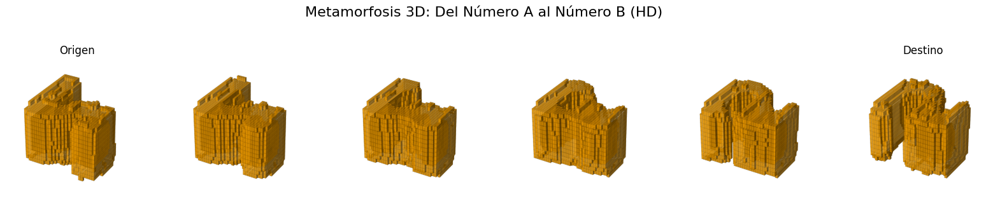

In [ ]:

# Interpolación 3D

def interpolacion_3d_hd(vae_model, cubo_a, cubo_b, n_pasos=6, factor_zoom=2):
    z1, _, _ = vae_model.encoder.predict(np.expand_dims(cubo_a, 0), verbose=0)
    z2, _, _ = vae_model.encoder.predict(np.expand_dims(cubo_b, 0), verbose=0)
    
    alphas = np.linspace(0, 1, n_pasos)
    z_interp = np.array([(1-a)*z1[0] + a*z2[0] for a in alphas])
    
    cubos_interp = vae_model.decoder.predict(z_interp, verbose=0)
    
    fig = plt.figure(figsize=(20, 4))
    fig.suptitle("Metamorfosis 3D: Del Número A al Número B (HD)", fontsize=16)
    
    for i in range(n_pasos):
        ax = fig.add_subplot(1, n_pasos, i + 1, projection='3d')
        cubo_hd = scipy.ndimage.zoom(cubos_interp[i,:,:,:,0], factor_zoom, order=1)
        ax.voxels(cubo_hd > 0.2, facecolors='orange', edgecolor=(0,0,0,0.05), alpha=0.7)
        ax.view_init(elev=30, azim=-60)
        ax.axis('off')
        if i == 0: ax.set_title("Origen")
        if i == n_pasos-1: ax.set_title("Destino")
        
    plt.show()

interpolacion_3d_hd(vae, X_test[2], X_test[30])

In [15]:
# Descargamos solo las etiquetas del dataset original
from tensorflow.keras.datasets import mnist
(_, _), (_, y_test) = mnist.load_data()

print(f"Etiquetas cargadas: {y_test.shape}")

Etiquetas cargadas: (10000,)


C:\Users\Marcos\AppData\Local\Temp\ipykernel_17616\3742678496.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colores = plt.cm.get_cmap('tab10', 10)
C:\Users\Marcos\AppData\Local\Temp\ipykernel_17616\3742678496.py:30: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(z_2d[idx, 0], z_2d[idx, 1], label=str(digit), alpha=0.7, cmap=colores)


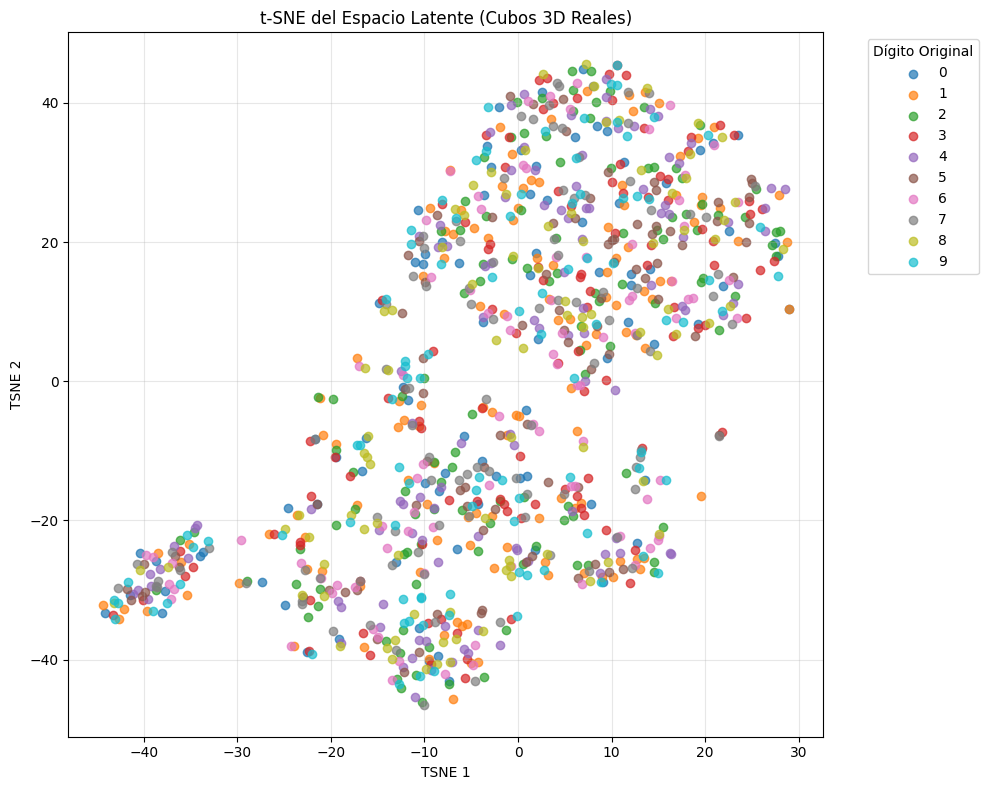

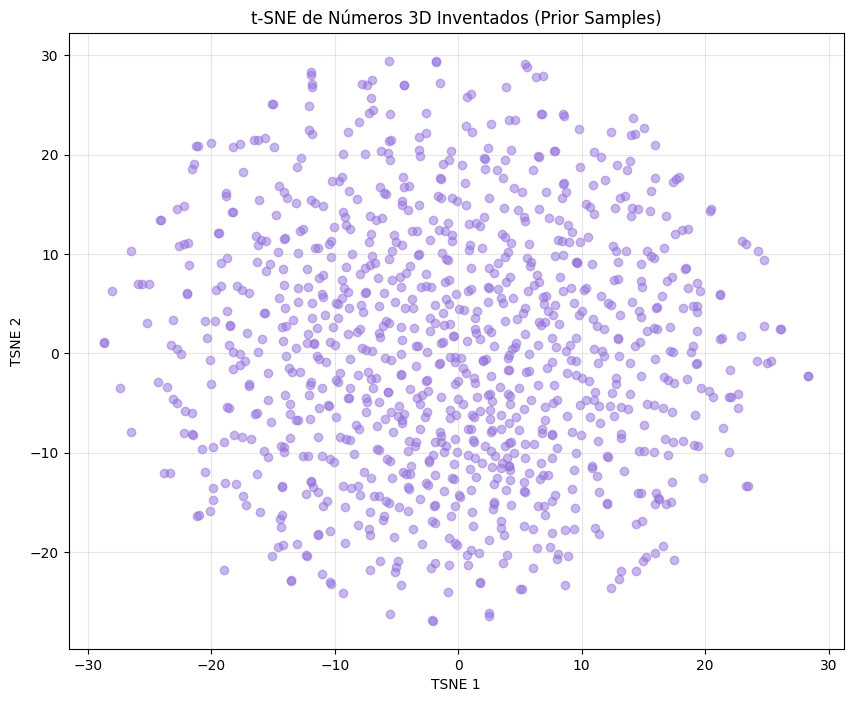

In [ ]:

# t-SNE del Espacio Latente 

from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

# t-SNE de los DATOS REALES 

# Cogemos una muestra (t-SNE es O(N^2), si le metemos todos los datos tarda demasiado)
n_muestras = 1000
x_sample = X_test[:n_muestras]
y_sample = y_test[:n_muestras]  

# Pasamos los cubos reales por el Encoder
# El encoder devuelve 3 cosas: [z_mean, z_log_var, z]. Cogemos el centro (z_mean).
z_mean, _, _ = vae.encoder.predict(x_sample, verbose=0)

# Reducimos el espacio de 32D a 2D para poder dibujarlo
tsne = TSNE(n_components=2, random_state=42)
z_2d = tsne.fit_transform(z_mean)

# Dibujamos el mapa coloreado por el número real
plt.figure(figsize=(10, 8))
colores = plt.cm.get_cmap('tab10', 10)

for digit in range(10):
    idx = (y_sample == digit)
    if np.any(idx): # Solo dibujamos si ese número está en la muestra
        plt.scatter(z_2d[idx, 0], z_2d[idx, 1], label=str(digit), alpha=0.7, cmap=colores)

plt.legend(title="Dígito Original", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title("t-SNE del Espacio Latente (Cubos 3D Reales)")
plt.xlabel("TSNE 1")
plt.ylabel("TSNE 2")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# t-SNE de los NÚMEROS INVENTADOS
# Vamos a ver si los números generados de la nada se agrupan igual de bien.

n_inventados = 1000
latent_dim = 32

# Generamos semillas aleatorias (ruido de la distribución normal)
z_random = np.random.normal(size=(n_inventados, latent_dim))

# El Decoder esculpe los cubos 3D a partir del ruido
recon_cubos = vae.decoder.predict(z_random, verbose=0)

# Binarizamos (como en tu ejemplo) para facilitar el trabajo al encoder
recon_binarios = (recon_cubos > 0.5).astype(np.float32)

# Volvemos a meter estos cubos "inventados" en el Encoder 
# para ver dónde cree el modelo que caen en su mapa mental.
z_recon_mean, _, _ = vae.encoder.predict(recon_binarios, verbose=0)

# Reducimos a 2D
tsne_gen = TSNE(n_components=2, random_state=42)
z_gen_2d = tsne_gen.fit_transform(z_recon_mean)

# Dibujamos el mapa de los "inventos"
plt.figure(figsize=(10, 8))
plt.scatter(z_gen_2d[:, 0], z_gen_2d[:, 1], alpha=0.5, color='mediumpurple')
plt.title("t-SNE de Números 3D Inventados (Prior Samples)")
plt.xlabel("TSNE 1")
plt.ylabel("TSNE 2")
plt.grid(True, alpha=0.3)
plt.show()

Calculando t-SNE (reduciendo de 32D a 2D)...


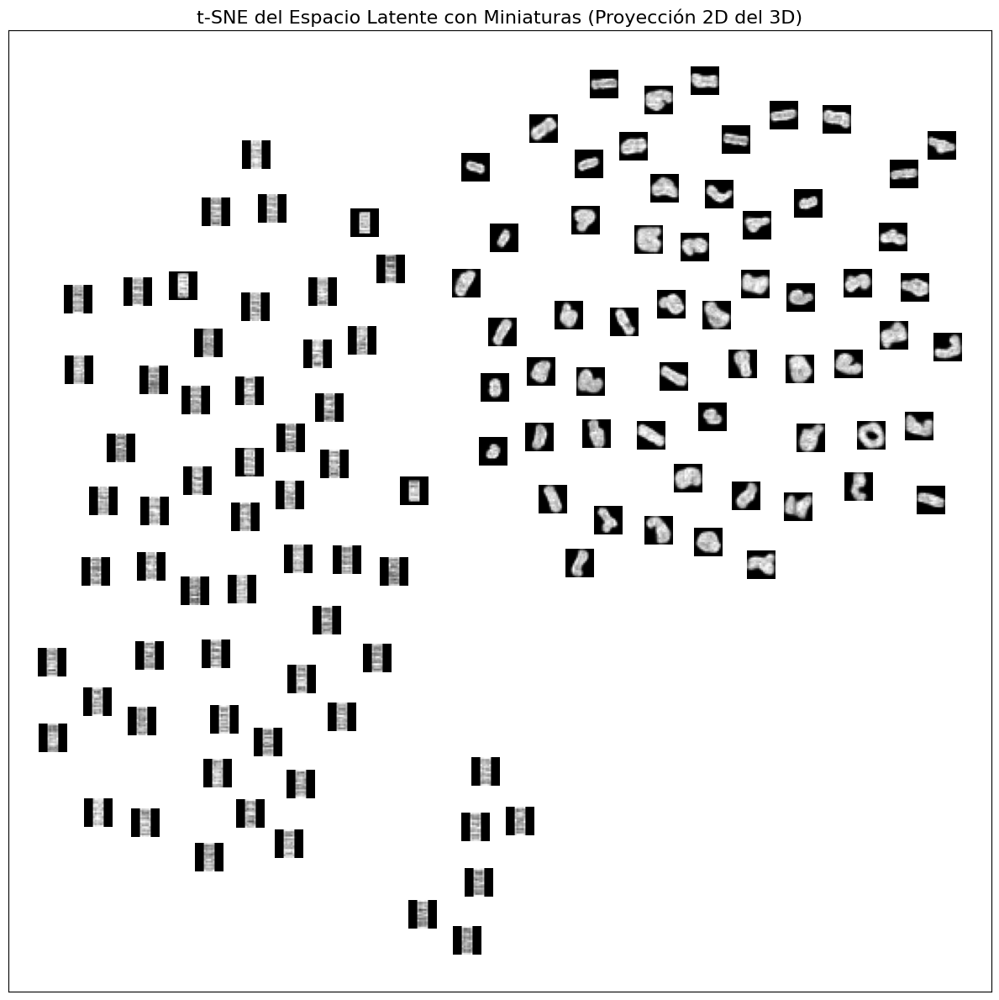

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from sklearn.manifold import TSNE

# Función para elegir puntos del t-SNE que estén bien distribuidos
def pick_spread_points(emb, n_show=150, seed=42):
    rng = np.random.default_rng(seed)
    idx = np.arange(emb.shape[0])
    rng.shuffle(idx)

    chosen = []
    # umbral basado en varianza global
    thr = 0.02 * np.var(emb, axis=0).sum()
    for i in idx:
        if not chosen:
            chosen.append(i); continue
        d2 = np.min(np.sum((emb[chosen] - emb[i])**2, axis=1))
        if d2 > thr:
            chosen.append(i)
        if len(chosen) >= n_show:
            break
    return np.array(chosen)

# Aplastamos el cubo para sacar una "foto" plana del número
def proyectar_cubo_a_2d(cubo_3d):
    # cubo_3d tiene forma (16, 16, 16, 1)
    # Hacemos una proyección aplanando el eje de profundidad (axis=1 o 2).
    # Los números están tumbados, aplastar el axis=1 o 2 nos dará la vista superior frontal.
    imagen_2d = np.max(cubo_3d[:, :, :, 0], axis=1) 
    return imagen_2d

# Función Principal adaptada a Keras
def tsne_con_miniaturas_3d(vae_model, datos_test, n_total=3000, n_show=150, zoom=1.5, seed=42):
    # Cogemos una muestra de los datos para no saturar la RAM
    X_sample = datos_test[:n_total]
    
    # Pasamos los datos por el Encoder para obtener el espacio latente (mu / z_mean)
    mu, _, _ = vae_model.encoder.predict(X_sample, verbose=0)
    
    # Pasamos 'mu' por el Decoder para obtener las reconstrucciones 3D
    recon = vae_model.decoder.predict(mu, verbose=0)

    print("Calculando t-SNE (reduciendo de 32D a 2D)...")
    tsne = TSNE(n_components=2, random_state=seed, init="pca", learning_rate="auto")
    emb = tsne.fit_transform(mu)
    
    # Filtramos para quedarnos con unos cuantos puntos esparcidos
    chosen = pick_spread_points(emb, n_show=n_show, seed=seed)

    # Preparamos el lienzo
    fig, ax = plt.subplots(figsize=(12, 12))
    ax.set_title("t-SNE del Espacio Latente con Miniaturas (Proyección 2D del 3D)", fontsize=16)
    ax.set_xticks([]); ax.set_yticks([])

    # Ponemos cada imagen reconstruida en su coordenada del t-SNE
    for i in chosen:
        # Cogemos el cubo reconstruido y lo aplastamos a 2D
        cubo = recon[i]
        thumb_2d = proyectar_cubo_a_2d(cubo)
        
        # Colocamos la miniatura
        ab = AnnotationBbox(
        
            OffsetImage(thumb_2d, zoom=zoom, cmap="gray"), 
            (emb[i, 0], emb[i, 1]), 
            frameon=False
        )
        ax.add_artist(ab)

    # Ajustamos los márgenes para que no se corten las imágenes de los bordes
    ax.set_xlim(emb[chosen, 0].min() - 5, emb[chosen, 0].max() + 5)
    ax.set_ylim(emb[chosen, 1].min() - 5, emb[chosen, 1].max() + 5)
    
    plt.tight_layout()
    plt.show()


# Llamamos a la función pasándole el modelo entrenado y el dataset de prueba
tsne_con_miniaturas_3d(vae, X_test, n_total=2000, n_show=150, zoom=1.5)

### VAE 3D (MMD)

In [19]:
import tensorflow as tf

def calcular_kernel_rbf(x, y, gamma=1.0):
    # Calcula la distancia matemática entre nubes de puntos
    x_sqnorms = tf.reduce_sum(tf.square(x), axis=1, keepdims=True)
    y_sqnorms = tf.reduce_sum(tf.square(y), axis=1, keepdims=True)
    distancias = x_sqnorms + tf.transpose(y_sqnorms) - 2.0 * tf.matmul(x, y, transpose_b=True)
    return tf.exp(-gamma * distancias)

def calcular_mmd(z_real, z_predicho):
    # Compara: el ruido ideal consigo mismo, nuestro latente consigo mismo, y ambos entre sí
    k_xx = calcular_kernel_rbf(z_real, z_real)
    k_yy = calcular_kernel_rbf(z_predicho, z_predicho)
    k_xy = calcular_kernel_rbf(z_real, z_predicho)
    
    # Si las nubes son iguales, esto da 0. Si son muy distintas, sube el error.
    return tf.reduce_mean(k_xx) + tf.reduce_mean(k_yy) - 2 * tf.reduce_mean(k_xy)

In [ ]:
class MMD_VAE3D(tf.keras.Model):
    def __init__(self, encoder, decoder, beta_mmd=5.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta_mmd = beta_mmd # El peso de la corrección
        
        # Monitores para ver las pérdidas durante el entrenamiento
        self.total_loss_tracker = tf.keras.metrics.Mean(name="total_loss")
        self.recon_loss_tracker = tf.keras.metrics.Mean(name="recon_loss")
        self.mmd_loss_tracker = tf.keras.metrics.Mean(name="mmd_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.recon_loss_tracker, self.mmd_loss_tracker]

    def train_step(self, data):
        # En caso de que vengan etiquetas, nos quedamos solo con la imagen
        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:
            # El Encoder lee los datos
            z_mean, z_log_var, z = self.encoder(data)
            
            # El Decoder esculpe la reconstrucción
            reconstruccion = self.decoder(z)
            
            # Perdida de reconstrucción (Compara píxel a píxel)
            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    tf.keras.losses.binary_crossentropy(data, reconstruccion), axis=(1, 2, 3)
                )
            )
            
            # NUEVA PÉRDIDA MMD
            # Creamos una nube de ruido puro (lo que queremos que imite)
            batch_size = tf.shape(z)[0]
            latent_dim = tf.shape(z)[1]
            z_ideal = tf.random.normal(shape=(batch_size, latent_dim))
            
            # Calculamos la distancia MMD
            mmd_loss = calcular_mmd(z_ideal, z)
            
            # Sumamos las pérdidas (multiplicando el MMD por su peso)
            total_loss = reconstruction_loss + (self.beta_mmd * mmd_loss)
            
        # Actualizamos la red neuronal
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        
        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(reconstruction_loss)
        self.mmd_loss_tracker.update_state(mmd_loss)
        
        return {
            "loss": self.total_loss_tracker.result(),
            "recon_loss": self.recon_loss_tracker.result(),
            "mmd_loss": self.mmd_loss_tracker.result(),
        }
        
    def call(self, inputs):
        _, _, z = self.encoder(inputs)
        return self.decoder(z)

In [ ]:
# Construimos las piezas usando las funciones que definimos más arriba
encoder, shape_before_flattening = build_encoder()
decoder = build_decoder(shape_before_flattening)

# Declaramos el nuevo modelo MMD uniendo esas piezas
vae = MMD_VAE3D(encoder, decoder, beta_mmd=100.0) 
vae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005))

Iniciando entrenamiento del Wasserstein Autoencoder (MMD)...
Epoch 1/50
313/313 [==============================] - 31s 97ms/step - loss: 1274.9937 - recon_loss: 888.6505 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 2/50
313/313 [==============================] - ETA: 0s - loss: 624.7594 - recon_loss: 597.0758 - mmd_loss: 0.0627

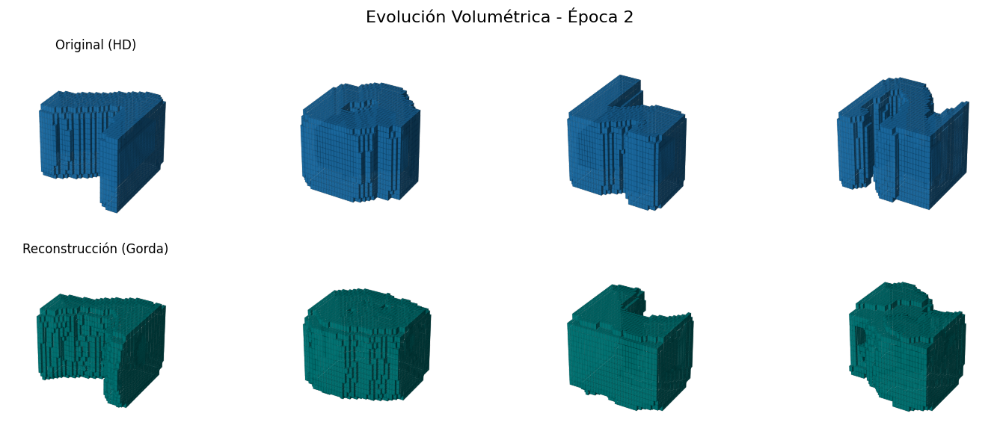

313/313 [==============================] - 80s 256ms/step - loss: 624.6912 - recon_loss: 597.0758 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 3/50
313/313 [==============================] - 30s 97ms/step - loss: 571.6596 - recon_loss: 558.4946 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 4/50
313/313 [==============================] - 31s 98ms/step - loss: 546.9374 - recon_loss: 538.5417 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 5/50
313/313 [==============================] - 31s 99ms/step - loss: 531.0879 - recon_loss: 521.8455 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 6/50
313/313 [==============================] - 30s 97ms/step - loss: 518.2630 - recon_loss: 508.2681 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_

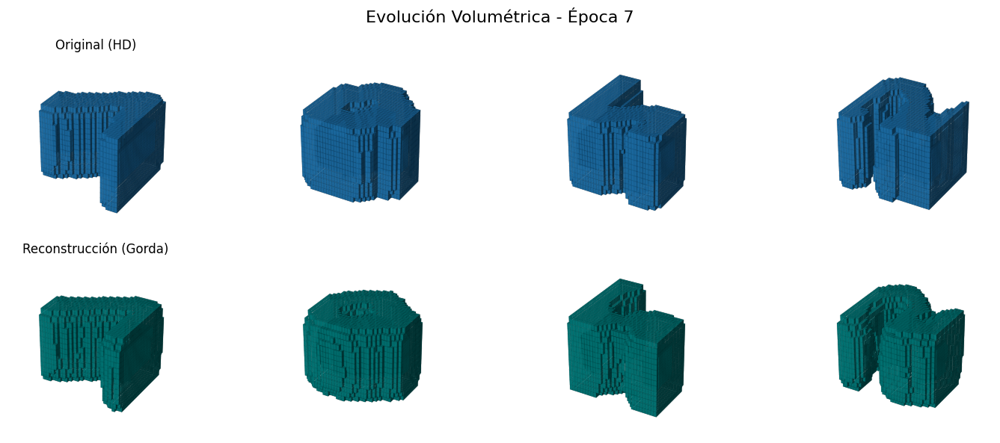

313/313 [==============================] - 82s 264ms/step - loss: 506.6392 - recon_loss: 498.7531 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 8/50
313/313 [==============================] - 31s 100ms/step - loss: 500.8842 - recon_loss: 491.5509 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 9/50
313/313 [==============================] - 31s 99ms/step - loss: 492.2698 - recon_loss: 485.4245 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 10/50
313/313 [==============================] - 31s 98ms/step - loss: 486.7937 - recon_loss: 480.1666 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 11/50
313/313 [==============================] - 30s 95ms/step - loss: 483.5842 - recon_loss: 476.1337 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - v

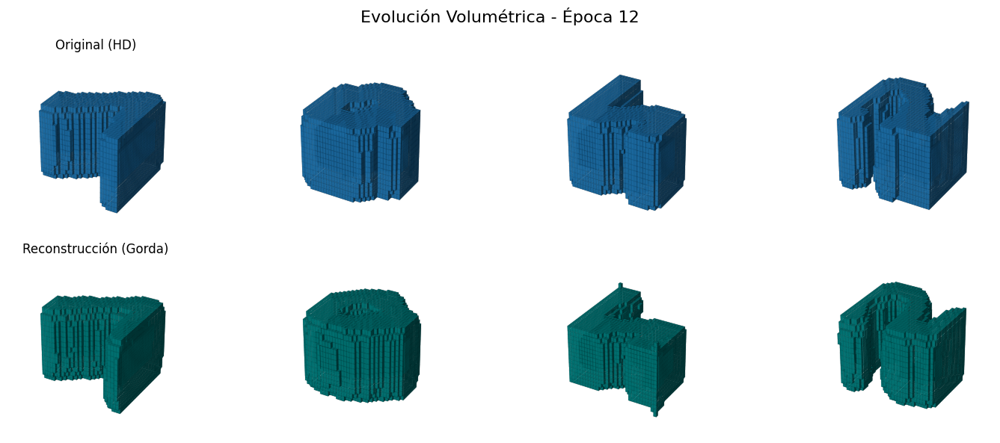

313/313 [==============================] - 87s 279ms/step - loss: 479.7327 - recon_loss: 472.4526 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 13/50
313/313 [==============================] - 30s 97ms/step - loss: 477.8981 - recon_loss: 469.5885 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 14/50
313/313 [==============================] - 31s 98ms/step - loss: 473.7468 - recon_loss: 466.9239 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 15/50
313/313 [==============================] - 31s 99ms/step - loss: 471.2017 - recon_loss: 464.6844 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 16/50
313/313 [==============================] - 30s 97ms/step - loss: 469.5032 - recon_loss: 462.2746 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - 

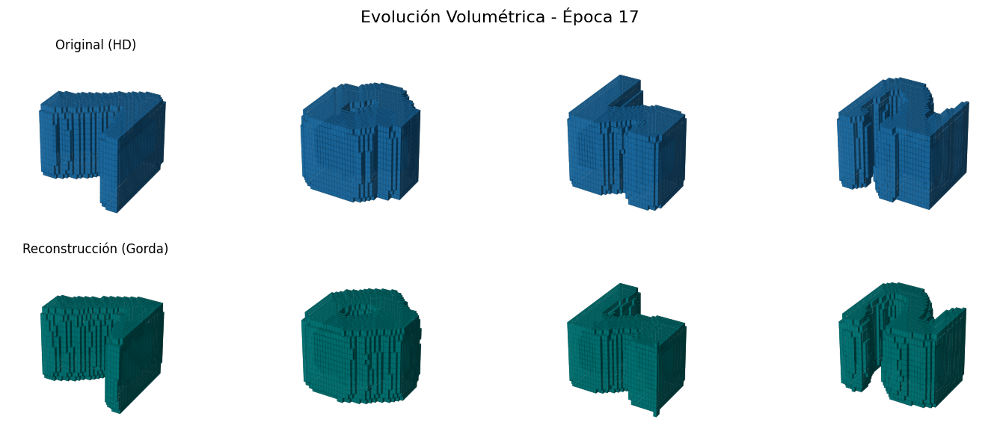

313/313 [==============================] - 86s 274ms/step - loss: 467.6207 - recon_loss: 460.5149 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 18/50
313/313 [==============================] - 30s 97ms/step - loss: 465.8216 - recon_loss: 458.5732 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 19/50
313/313 [==============================] - 31s 98ms/step - loss: 463.1538 - recon_loss: 457.1591 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 20/50
313/313 [==============================] - 31s 99ms/step - loss: 462.0120 - recon_loss: 455.6365 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 21/50
313/313 [==============================] - 30s 97ms/step - loss: 461.8568 - recon_loss: 454.2094 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - 

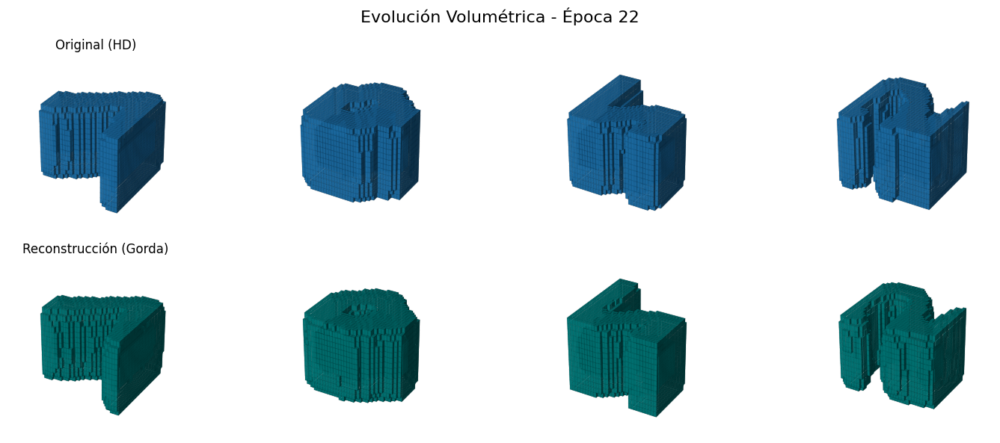

313/313 [==============================] - 88s 281ms/step - loss: 458.8002 - recon_loss: 453.0015 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 23/50
313/313 [==============================] - 31s 98ms/step - loss: 459.6881 - recon_loss: 451.8556 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 24/50
313/313 [==============================] - 31s 99ms/step - loss: 455.4583 - recon_loss: 451.0736 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 25/50
313/313 [==============================] - 31s 99ms/step - loss: 455.3850 - recon_loss: 449.8846 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 26/50
313/313 [==============================] - 30s 97ms/step - loss: 455.0904 - recon_loss: 448.9464 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - 

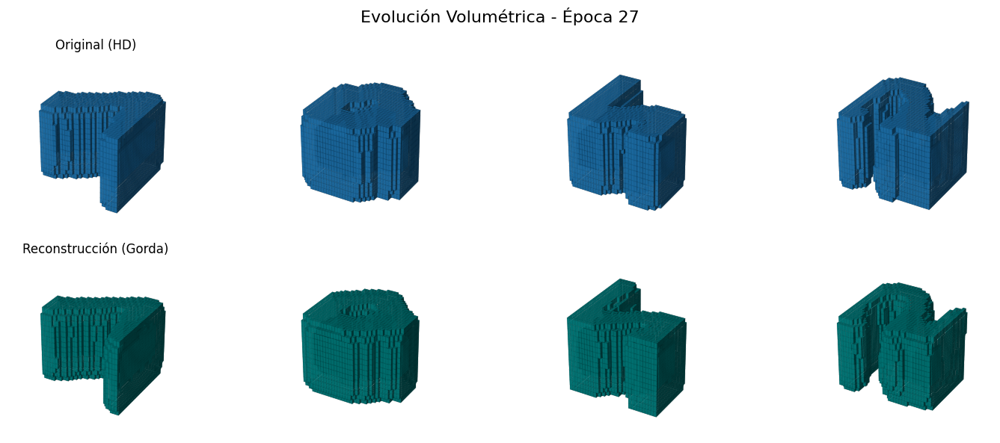

313/313 [==============================] - 89s 284ms/step - loss: 452.9982 - recon_loss: 448.1470 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 28/50
313/313 [==============================] - 30s 97ms/step - loss: 455.0663 - recon_loss: 447.5434 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 29/50
313/313 [==============================] - 31s 98ms/step - loss: 453.4279 - recon_loss: 446.9793 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 30/50
313/313 [==============================] - 31s 99ms/step - loss: 453.4136 - recon_loss: 446.3071 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 31/50
313/313 [==============================] - 30s 97ms/step - loss: 450.0393 - recon_loss: 445.6646 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - 

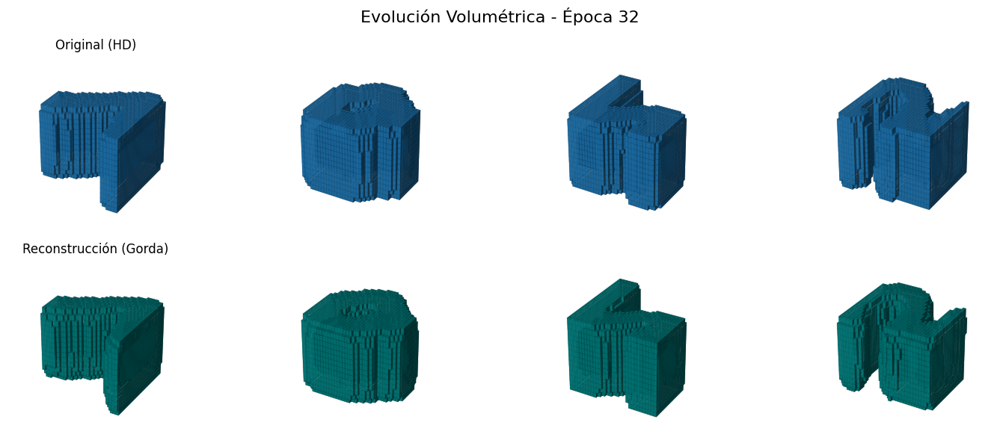

313/313 [==============================] - 87s 280ms/step - loss: 451.2530 - recon_loss: 444.9392 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 33/50
313/313 [==============================] - 30s 97ms/step - loss: 451.6842 - recon_loss: 444.5679 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 34/50
313/313 [==============================] - 31s 98ms/step - loss: 449.7201 - recon_loss: 443.9936 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 35/50
313/313 [==============================] - 31s 99ms/step - loss: 450.1035 - recon_loss: 443.5310 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 36/50
313/313 [==============================] - 30s 97ms/step - loss: 449.7088 - recon_loss: 443.1009 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - 

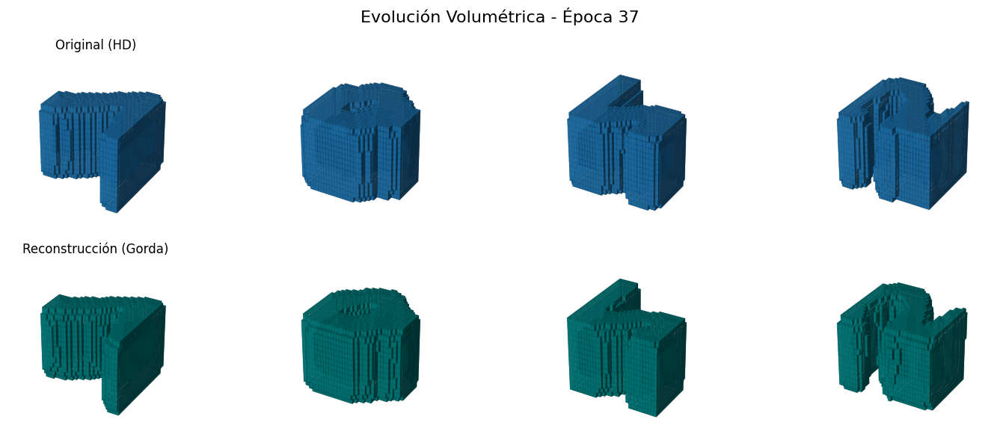

313/313 [==============================] - 88s 282ms/step - loss: 448.7111 - recon_loss: 442.5734 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 38/50
313/313 [==============================] - 31s 98ms/step - loss: 449.1723 - recon_loss: 442.3673 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 39/50
313/313 [==============================] - 31s 98ms/step - loss: 446.1199 - recon_loss: 441.8340 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 40/50
313/313 [==============================] - 31s 99ms/step - loss: 447.5741 - recon_loss: 441.5304 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 41/50
313/313 [==============================] - 31s 98ms/step - loss: 446.4593 - recon_loss: 440.9510 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - 

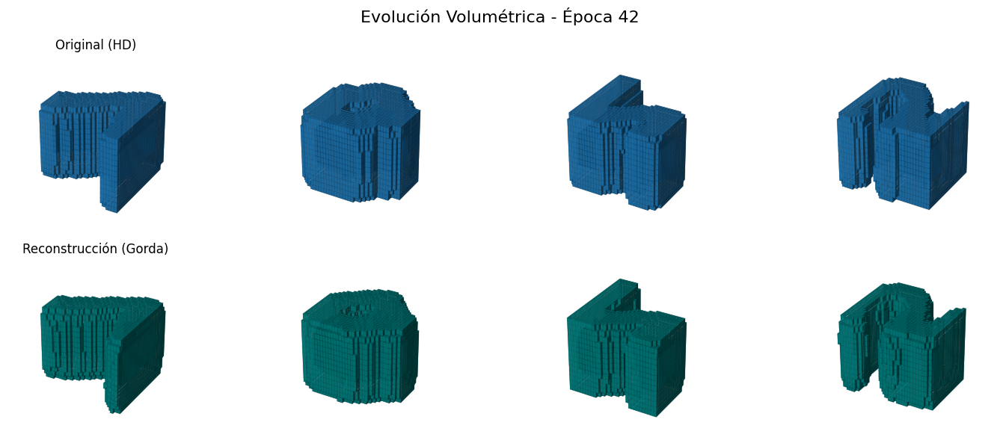

313/313 [==============================] - 87s 278ms/step - loss: 446.0346 - recon_loss: 440.8105 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 43/50
313/313 [==============================] - 31s 98ms/step - loss: 446.0472 - recon_loss: 440.1986 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 44/50
313/313 [==============================] - 31s 98ms/step - loss: 448.4497 - recon_loss: 439.9282 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 45/50
313/313 [==============================] - 31s 99ms/step - loss: 444.4825 - recon_loss: 439.7696 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 46/50
313/313 [==============================] - 30s 97ms/step - loss: 445.9570 - recon_loss: 439.4610 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - 

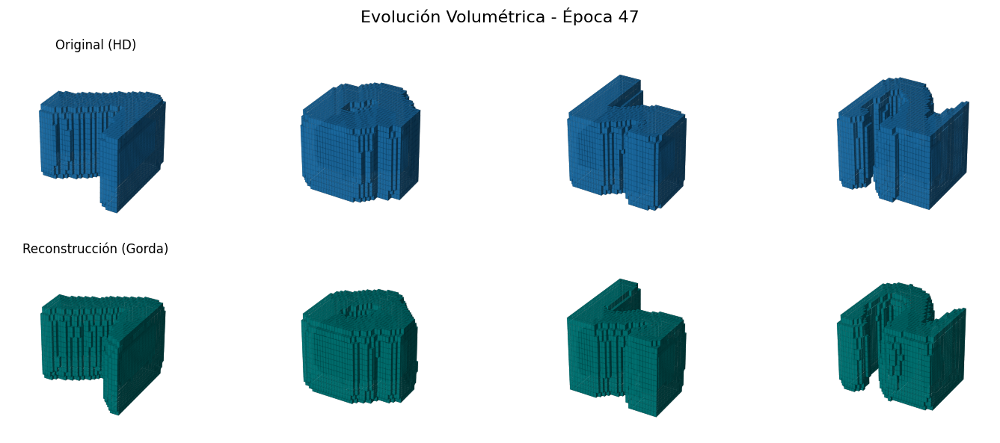

313/313 [==============================] - 110s 353ms/step - loss: 444.8435 - recon_loss: 438.9991 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 48/50
313/313 [==============================] - 30s 95ms/step - loss: 443.5748 - recon_loss: 438.6946 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 49/50
313/313 [==============================] - 30s 96ms/step - loss: 444.0072 - recon_loss: 438.8933 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00
Epoch 50/50
313/313 [==============================] - 30s 95ms/step - loss: 442.0971 - recon_loss: 438.4788 - mmd_loss: 0.0627 - val_total_loss: 0.0000e+00 - val_recon_loss: 0.0000e+00 - val_mmd_loss: 0.0000e+00


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

# Preparamos nuestro visor con los 4 ejemplos que querías
indices_personalizados = [0, 6, 2, 30] 
mis_4_ejemplos = X_test[indices_personalizados]

visor_callback = VisorReconstruccion3D(
    datos_prueba=mis_4_ejemplos, 
    num_ejemplos=4, 
    threshold_orig=0.05, 
    threshold_recon=0.1,  # Umbral bajo para ver cómo moldea la "niebla"
    factor_zoom=2         # Calidad HD
)

# Configurar el earlyStopping
early_stopping = EarlyStopping(
    monitor='val_loss',        # Vigila el error total (Reconstrucción + MMD)
    min_delta=0.5,             
    patience=5,                # Si pasan 5 épocas sin mejorar, se detiene
    restore_best_weights=True  # Se queda con la mejor versión
)

# Entrenar
print("Iniciando entrenamiento del Wasserstein Autoencoder (MMD)...")
history = vae.fit(
    X_train, X_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, X_test),
    callbacks=[visor_callback, early_stopping]
)

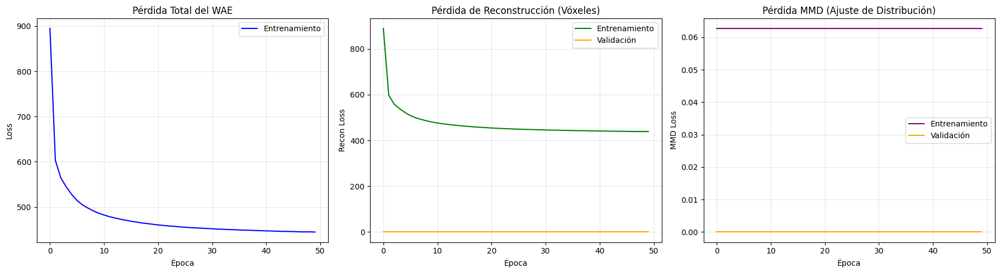

In [ ]:

# Gráficas de Pérdidas del Entrenamiento (MMD)

import matplotlib.pyplot as plt

plt.figure(figsize=(18, 5))

# Pérdida Total (Reconstrucción + MMD)
plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], label='Entrenamiento', color='blue')
if 'val_loss' in history.history:
    plt.plot(history.history['val_loss'], label='Validación', color='orange')
plt.title('Pérdida Total del WAE')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# Pérdida de Reconstrucción (El moldeado 3D)
plt.subplot(1, 3, 2)
plt.plot(history.history['recon_loss'], label='Entrenamiento', color='green')
if 'val_recon_loss' in history.history:
    plt.plot(history.history['val_recon_loss'], label='Validación', color='orange')
plt.title('Pérdida de Reconstrucción (Vóxeles)')
plt.xlabel('Época')
plt.ylabel('Recon Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# Pérdida MMD (El orden del mapa mental)
plt.subplot(1, 3, 3)
plt.plot(history.history['mmd_loss'], label='Entrenamiento', color='purple')
if 'val_mmd_loss' in history.history:
    plt.plot(history.history['val_mmd_loss'], label='Validación', color='orange')
plt.title('Pérdida MMD (Ajuste de Distribución)')
plt.xlabel('Época')
plt.ylabel('MMD Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

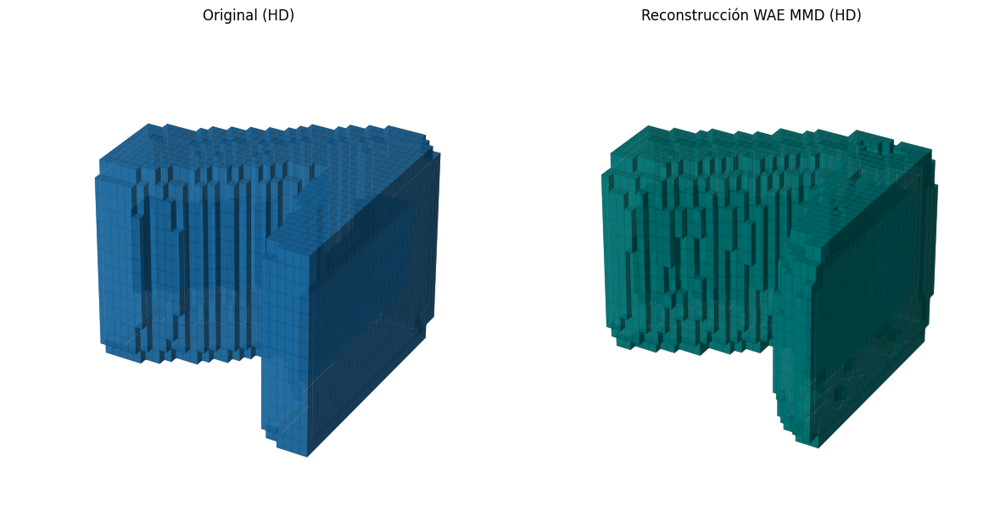

In [ ]:
import scipy.ndimage


# Comparativa de Reconstrucción Final 

def visualizar_resultado_hd(data, threshold_orig=0.05, threshold_recon=0.15, factor_zoom=2):
    fig = plt.figure(figsize=(12, 6))
    
    # Original
    ax1 = fig.add_subplot(121, projection='3d')
    cubo_orig_suave = scipy.ndimage.zoom(data[0,:,:,:,0], factor_zoom, order=1)
    ax1.voxels(cubo_orig_suave > threshold_orig, facecolors='#1f77b4', edgecolor=(0,0,0,0.05), alpha=0.8)
    ax1.set_title("Original (HD)")
    ax1.view_init(elev=30, azim=-60)
    ax1.axis('off')
    
    # Reconstrucción MMD 
    recon = vae.predict(data[:1], verbose=0)
    ax2 = fig.add_subplot(122, projection='3d')
    cubo_recon_suave = scipy.ndimage.zoom(recon[0,:,:,:,0], factor_zoom, order=1)
    ax2.voxels(cubo_recon_suave > threshold_recon, facecolors='teal', edgecolor=(0,0,0,0.05), alpha=0.8)
    ax2.set_title("Reconstrucción WAE MMD (HD)")
    ax2.view_init(elev=30, azim=-60)
    ax2.axis('off')
    
    plt.tight_layout()
    plt.show()

# Visualizamos el primer ejemplo en HD
visualizar_resultado_hd(X_test[0:1], threshold_recon=0.15)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage

# Número de dígitos 3D inventados que queremos generar
n_imagenes = 5
dim_latente = 32 # La dimensión latente de nuestro WAE para MNIST 3D
factor_zoom = 2
threshold_recon = 0.1

# Muestreamos ruido aleatorio del espacio prior N(0, I)
z_sample = np.random.normal(0, 1, size=(n_imagenes, dim_latente))

# Pasamos el ruido por el Decoder del WAE 

volumenes_generados = decoder.predict(z_sample)

# 3. Renderizamos los volúmenes generados
fig = plt.figure(figsize=(15, 4))
fig.suptitle("Muestras volumétricas generadas a partir de ruido (WAE-MMD)", fontsize=16)

for i in range(n_imagenes):
    ax = fig.add_subplot(1, n_imagenes, i + 1, projection='3d')
    
    # Extraemos el cubo, lo suavizamos y aplicamos el umbral
    cubo_bruto = volumenes_generados[i, :, :, :, 0]
    cubo_suave = scipy.ndimage.zoom(cubo_bruto, factor_zoom, order=1)
    cubo_final = cubo_suave > threshold_recon
    
    ax.voxels(cubo_final, facecolors='teal', edgecolor=(0, 0, 0, 0.05), alpha=0.9)
    ax.view_init(elev=30, azim=-60)
    ax.axis('off')
    ax.set_title(f"Muestra {i+1}")

plt.tight_layout()
plt.show()

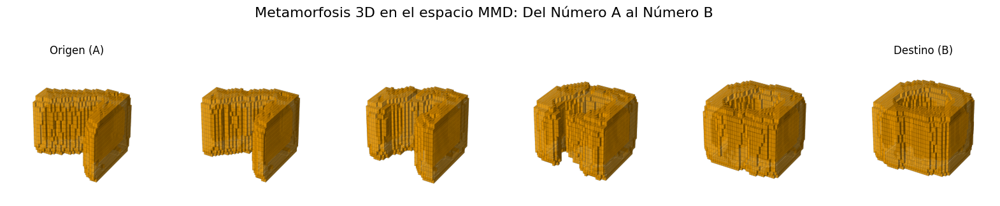

In [ ]:

# Interpolación Lineal en el Espacio Latente 

def interpolacion_3d_hd(vae_model, cubo_a, cubo_b, n_pasos=6, factor_zoom=2, threshold=0.15):
    # Conseguimos el mapa mental (z_mean) de ambos extremos
    z1, _, _ = vae_model.encoder.predict(np.expand_dims(cubo_a, 0), verbose=0)
    z2, _, _ = vae_model.encoder.predict(np.expand_dims(cubo_b, 0), verbose=0)
    
    # Calculamos los pasos intermedios entre z1 y z2
    alphas = np.linspace(0, 1, n_pasos)
    z_interp = np.array([(1-a)*z1[0] + a*z2[0] for a in alphas])
    
    # El decoder esculpe la metamorfosis
    cubos_interp = vae_model.decoder.predict(z_interp, verbose=0)
    
    fig = plt.figure(figsize=(20, 4))
    fig.suptitle("Metamorfosis 3D en el espacio MMD: Del Número A al Número B", fontsize=16)
    
    for i in range(n_pasos):
        ax = fig.add_subplot(1, n_pasos, i + 1, projection='3d')
        cubo_hd = scipy.ndimage.zoom(cubos_interp[i,:,:,:,0], factor_zoom, order=1)
        ax.voxels(cubo_hd > threshold, facecolors='orange', edgecolor=(0,0,0,0.05), alpha=0.7)
        ax.view_init(elev=30, azim=-60)
        ax.axis('off')
        if i == 0: ax.set_title("Origen (A)")
        if i == n_pasos-1: ax.set_title("Destino (B)")
        
    plt.show()

# Transición entre el ejemplo 0 y el ejemplo 20
interpolacion_3d_hd(vae, X_test[0], X_test[20], threshold=0.15)

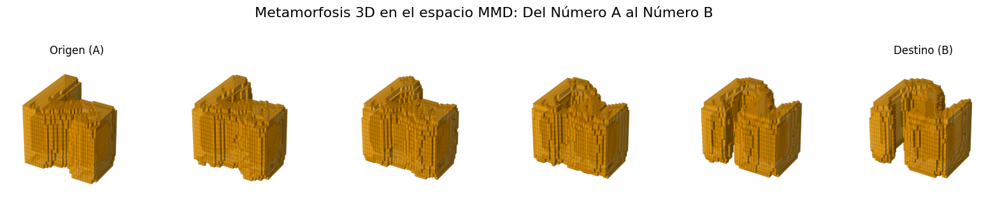

In [ ]:

# Interpolación Lineal en el Espacio Latente (HD)

def interpolacion_3d_hd(vae_model, cubo_a, cubo_b, n_pasos=6, factor_zoom=2, threshold=0.15):
    # Conseguimos el mapa mental (z_mean) de ambos extremos
    z1, _, _ = vae_model.encoder.predict(np.expand_dims(cubo_a, 0), verbose=0)
    z2, _, _ = vae_model.encoder.predict(np.expand_dims(cubo_b, 0), verbose=0)
    
    # Calculamos los pasos intermedios entre z1 y z2
    alphas = np.linspace(0, 1, n_pasos)
    z_interp = np.array([(1-a)*z1[0] + a*z2[0] for a in alphas])
    
    # El decoder esculpe la metamorfosis
    cubos_interp = vae_model.decoder.predict(z_interp, verbose=0)
    
    fig = plt.figure(figsize=(20, 4))
    fig.suptitle("Metamorfosis 3D en el espacio MMD: Del Número A al Número B", fontsize=16)
    
    for i in range(n_pasos):
        ax = fig.add_subplot(1, n_pasos, i + 1, projection='3d')
        cubo_hd = scipy.ndimage.zoom(cubos_interp[i,:,:,:,0], factor_zoom, order=1)
        ax.voxels(cubo_hd > threshold, facecolors='orange', edgecolor=(0,0,0,0.05), alpha=0.7)
        ax.view_init(elev=30, azim=-60)
        ax.axis('off')
        if i == 0: ax.set_title("Origen (A)")
        if i == n_pasos-1: ax.set_title("Destino (B)")
        
    plt.show()

# Transición entre el ejemplo 0 y el ejemplo 20
interpolacion_3d_hd(vae, X_test[2], X_test[30], threshold=0.15)

In [42]:
# Descargamos las etiquetas (los números del 0 al 9 reales) para poder colorear el mapa
from tensorflow.keras.datasets import mnist
(_, _), (_, y_test) = mnist.load_data()

print(f"Etiquetas cargadas correctamente: {y_test.shape}")

Etiquetas cargadas correctamente: (10000,)


C:\Users\Marcos\AppData\Local\Temp\ipykernel_21904\2628410977.py:22: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colores = plt.cm.get_cmap('tab10', 10)
C:\Users\Marcos\AppData\Local\Temp\ipykernel_21904\2628410977.py:26: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(z_2d[idx, 0], z_2d[idx, 1], label=str(digit), alpha=0.7, cmap=colores)


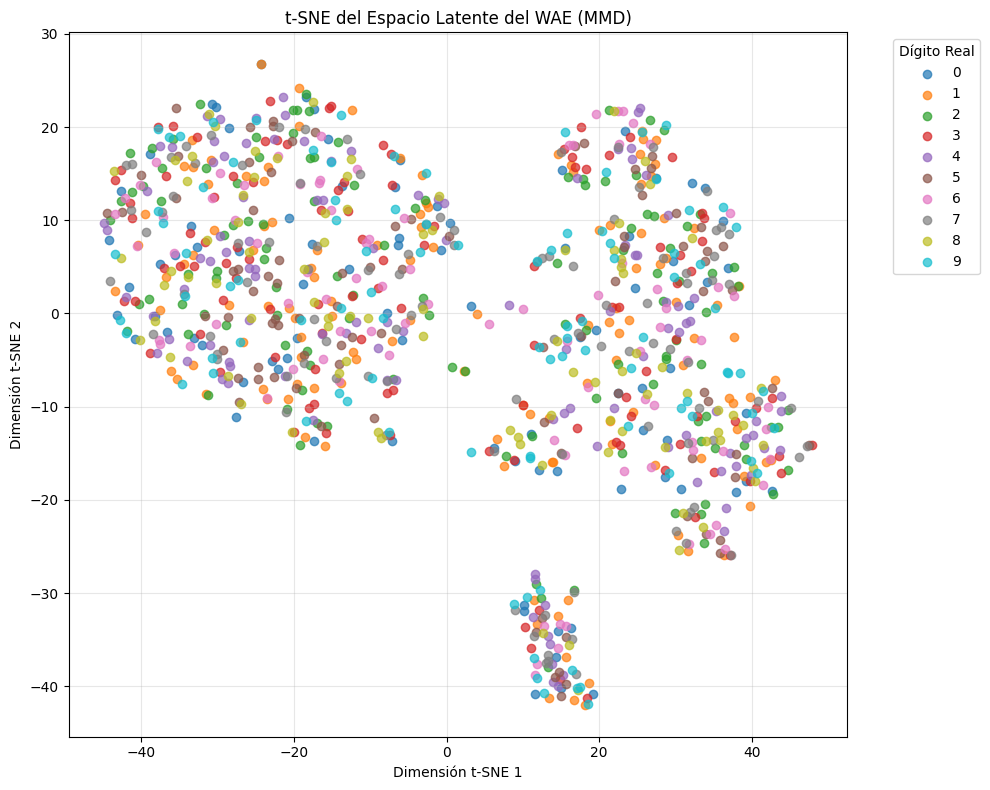

In [ ]:

# t-SNE del Espacio Latente MMD (Agrupación)

from sklearn.manifold import TSNE
import numpy as np

n_muestras = 1000
x_sample = X_test[:n_muestras]

# Codificamos los datos reales
z_mean, _, _ = vae.encoder.predict(x_sample, verbose=0)

# Reducimos a 2D
tsne = TSNE(n_components=2, random_state=42, init='pca', learning_rate='auto')
z_2d = tsne.fit_transform(z_mean)

plt.figure(figsize=(10, 8))

# Si tienes las etiquetas y_test listas, las usa para colorear
try:
    y_sample = y_test[:n_muestras]
    colores = plt.cm.get_cmap('tab10', 10)
    for digit in range(10):
        idx = (y_sample == digit)
        if np.any(idx):
            plt.scatter(z_2d[idx, 0], z_2d[idx, 1], label=str(digit), alpha=0.7, cmap=colores)
    plt.legend(title="Dígito Real", bbox_to_anchor=(1.05, 1), loc='upper left')
except NameError:
    # Si no hay etiquetas, dibuja un mapa de densidad monocromático
    plt.scatter(z_2d[:, 0], z_2d[:, 1], alpha=0.6, color='teal', label="Estructura MMD")
    plt.legend()

plt.title("t-SNE del Espacio Latente del WAE (MMD)")
plt.xlabel("Dimensión t-SNE 1")
plt.ylabel("Dimensión t-SNE 2")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

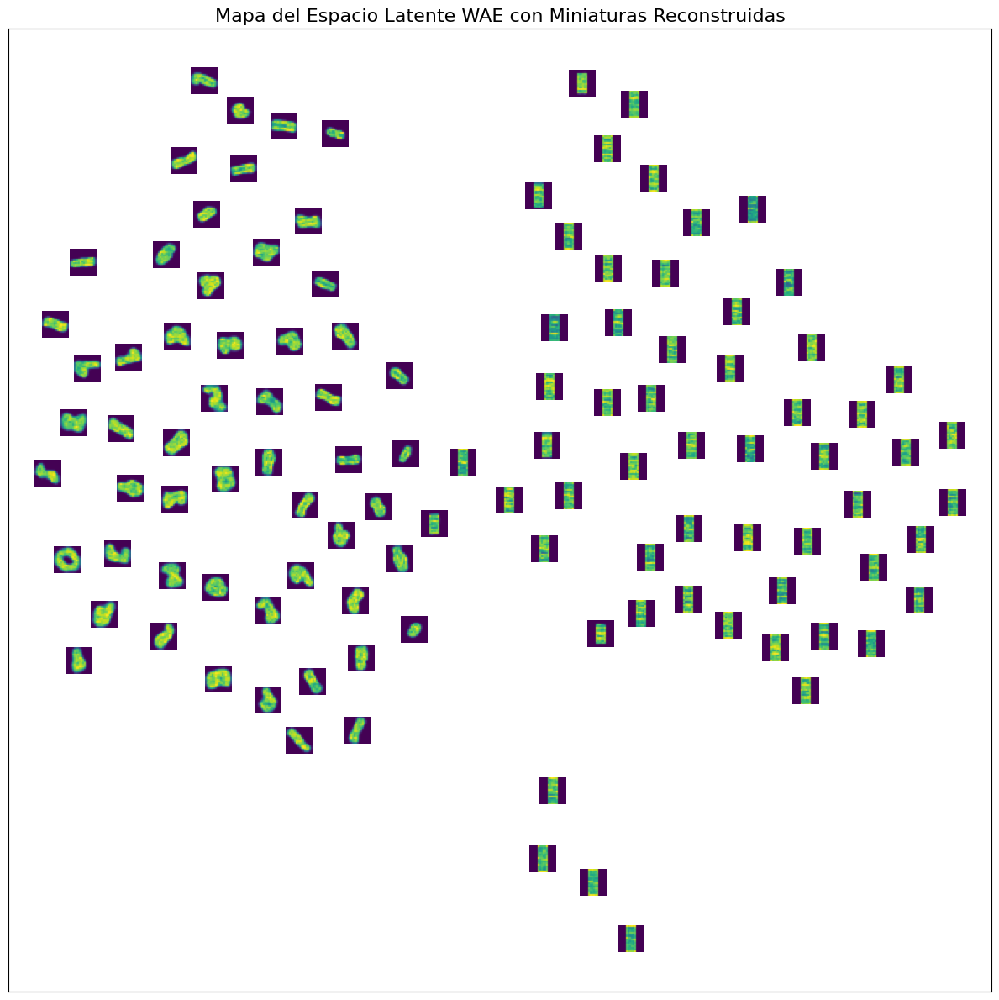

In [ ]:

#t-SNE del Espacio Latente con Miniaturas Proyectadas

from matplotlib.offsetbox import OffsetImage, AnnotationBbox

def pick_spread_points(emb, n_show=150, seed=42):
    rng = np.random.default_rng(seed)
    idx = np.arange(emb.shape[0])
    rng.shuffle(idx)
    chosen = []
    thr = 0.02 * np.var(emb, axis=0).sum()
    for i in idx:
        if not chosen:
            chosen.append(i); continue
        d2 = np.min(np.sum((emb[chosen] - emb[i])**2, axis=1))
        if d2 > thr:
            chosen.append(i)
        if len(chosen) >= n_show:
            break
    return np.array(chosen)

def proyectar_cubo_a_2d(cubo_3d):
    return np.max(cubo_3d[:, :, :, 0], axis=1)

def tsne_con_miniaturas_3d(vae_model, datos_test, n_total=2000, n_show=120, zoom=1.4, seed=42):
    X_sample = datos_test[:n_total]
    mu, _, _ = vae_model.encoder.predict(X_sample, verbose=0)
    recon = vae_model.decoder.predict(mu, verbose=0)

    tsne = TSNE(n_components=2, random_state=seed, init="pca", learning_rate="auto")
    emb = tsne.fit_transform(mu)
    chosen = pick_spread_points(emb, n_show=n_show, seed=seed)

    fig, ax = plt.subplots(figsize=(12, 12))
    ax.set_title("Mapa del Espacio Latente WAE con Miniaturas Reconstruidas", fontsize=16)
    ax.set_xticks([]); ax.set_yticks([])

    for i in chosen:
        thumb_2d = proyectar_cubo_a_2d(recon[i])
        ab = AnnotationBbox(
            OffsetImage(thumb_2d, zoom=zoom, cmap="viridis"), # 'viridis' destaca genial los volúmenes MMD
            (emb[i, 0], emb[i, 1]), 
            frameon=False
        )
        ax.add_artist(ab)

    ax.set_xlim(emb[chosen, 0].min() - 5, emb[chosen, 0].max() + 5)
    ax.set_ylim(emb[chosen, 1].min() - 5, emb[chosen, 1].max() + 5)
    plt.tight_layout()
    plt.show()

# Dibujamos unas 120 miniaturas distribuidas uniformemente
tsne_con_miniaturas_3d(vae, X_test, n_total=2000, n_show=120, zoom=1.4)